 # Required Imports 

In [225]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor


In [226]:
# reading the csv file
df = pd.read_csv('NFLX.csv')

# Dimension 
print(f"\nDimensions: {df.shape}")

#Converting Date coloumn into datetime objects for sorting
df['Date'] = pd.to_datetime(df['Date'])

#Sorting the df according to acending order
df= df.sort_values(by='Date')

# Information regarding data types
print("\nData Info: ")
df.info()


Dimensions: (251, 7)

Data Info: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       251 non-null    datetime64[ns]
 1   Open       251 non-null    float64       
 2   High       251 non-null    float64       
 3   Low        251 non-null    float64       
 4   Close      251 non-null    float64       
 5   Adj Close  251 non-null    float64       
 6   Volume     251 non-null    int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 13.9 KB


# Exploration and Analysis

Descriptive Statistics:
                                Date     Open     High      Low    Close  \
count                            251 251.0000 251.0000 251.0000 251.0000   
mean   2023-08-01 05:44:13.386454272 404.1814 409.7547 398.9584 404.2705   
min              2023-02-01 00:00:00 287.3400 297.4500 285.3300 292.7600   
25%              2023-05-02 12:00:00 348.9950 356.8600 344.4900 348.1200   
50%              2023-08-02 00:00:00 412.0000 418.8400 407.4000 411.6900   
75%              2023-10-30 12:00:00 444.7300 448.5750 439.1750 444.9450   
max              2024-01-31 00:00:00 571.3500 579.6400 562.6800 575.7900   
std                              NaN  60.8499  61.3187  60.7226  61.1937   

       Adj Close          Volume  
count   251.0000        251.0000  
mean    404.2705  6,135,307.9681  
min     292.7600  1,404,700.0000  
25%     348.1200  3,966,000.0000  
50%     411.6900  5,128,900.0000  
75%     444.9450  6,880,600.0000  
max     575.7900 28,074,400.0000  
std      61

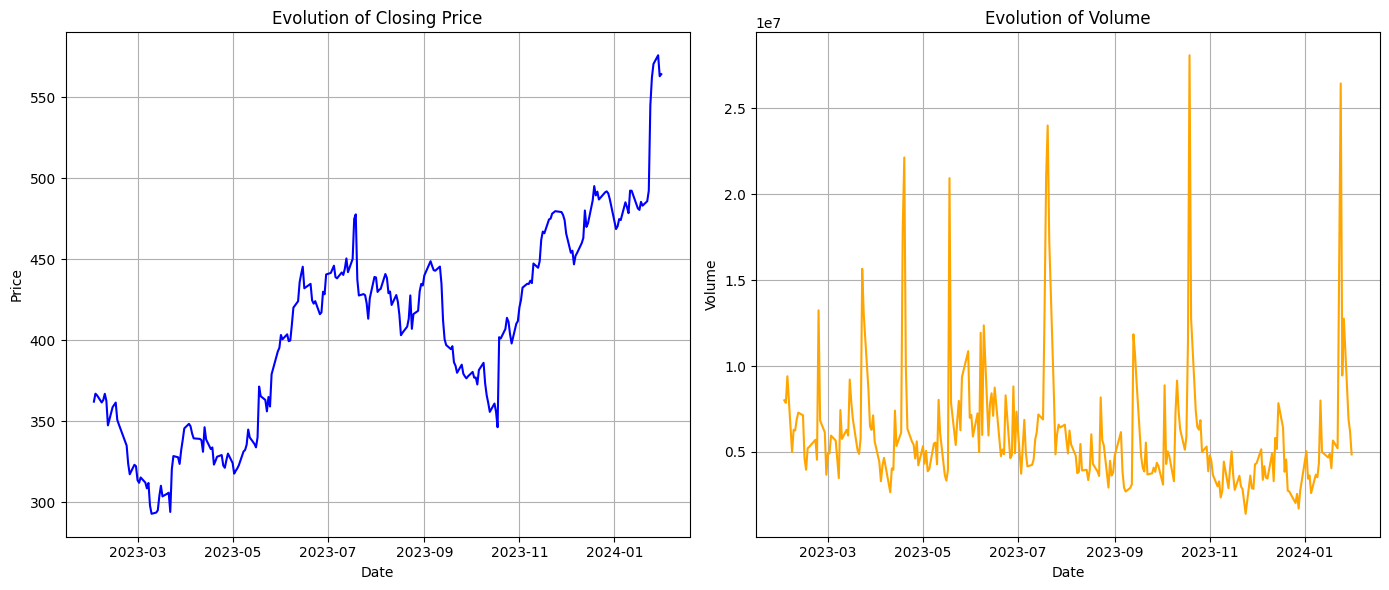

In [227]:
print("Descriptive Statistics:")
print(df.describe())

plt.figure(figsize=(14,6))

# Plot Closing Price
plt.subplot(1, 2, 1)
plt.plot(df['Date'], df['Close'], color='blue')
plt.title('Evolution of Closing Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.grid(True)

# Plot Volume
plt.subplot(1, 2, 2)
plt.plot(df['Date'], df['Volume'], color='orange')
plt.title('Evolution of Volume')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.grid(True)

plt.tight_layout()
plt.show()

# Features,Target and data preparation

In [228]:
# 1. Treatment of the Date spine (Set as index and sorting)
df= df.sort_values(by='Date')

# Set the index as date to enable date based searching
df.set_index('Date', inplace=True)

if df.isnull().sum().sum() > 0:
    print("Missing values found. Filling with previous day's value...")
    df.fillna(method='ffill', inplace=True)
else:
    print("No missing values found.")

# Defining the features and target
df['Amplitude'] = df['High'] - df['Low']

df['Day_of_Week'] = df.index.dayofweek

df['Prev_Close'] = df['Close'].shift(1)

# 2. Treatment of missing amounts
# check if there are any missing values in the df
if df.isnull().sum().sum() > 0:
    print(f"Found {df.isnull().sum().sum()} missing values. Dropping them...")
    df = df.dropna()
else:
    print("No missing values found.")

features = ['Open','High','Low' ,'Volume','Prev_Close','Day_of_Week','Amplitude']

target = 'Close'

X = df[features]
y=  df[target]

print(f"The length of the every column in  features {len(X)}")

No missing values found.
Found 1 missing values. Dropping them...
The length of the every column in  features 250


# Temporal Train / Test Split

In [229]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("Dates in Test set:", X_test.index[0], "to", X_test.index[-1])

# Checking the length of the test and train
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Training samples: {len(y_train)}")


Dates in Test set: 2023-11-17 00:00:00 to 2024-01-31 00:00:00
Training samples: 200
Testing samples: 50
Training samples: 200


# Linear Regression Model

--- Linear Regression Results ---
R^2 Score: 0.9892
MAE: 2.2536
RMSE: 3.1718


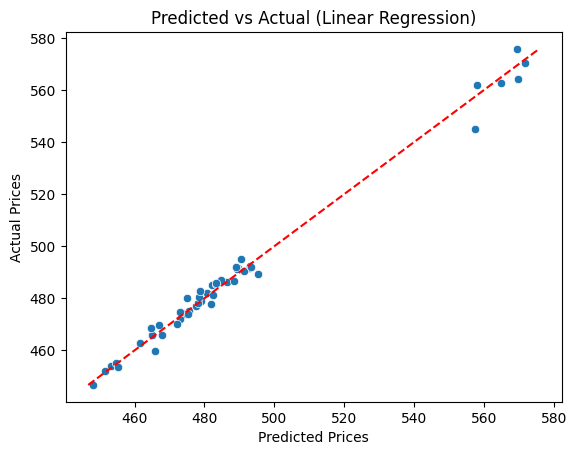

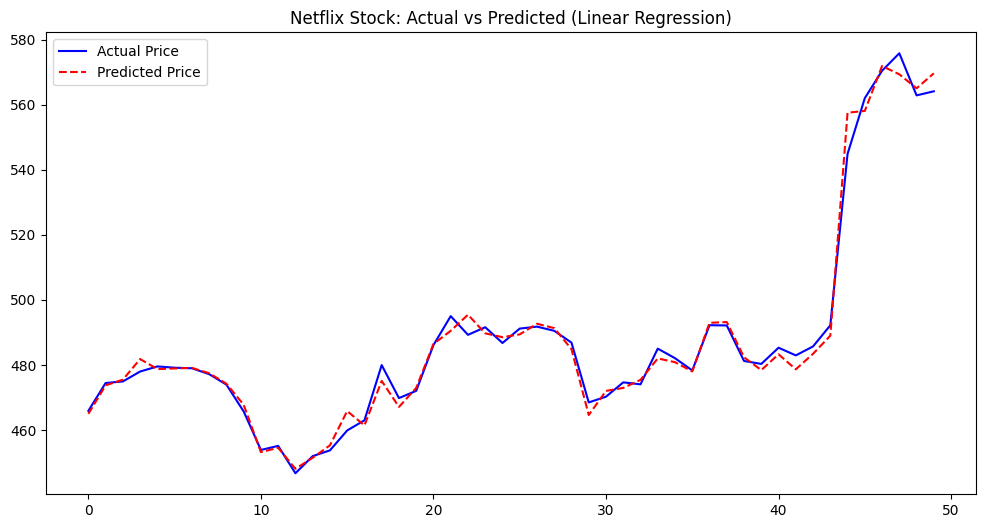

In [230]:
# Initialize the model
lr_model = LinearRegression()

# Train using training set
lr_model.fit(X_train,y_train)

# Make predictions on the remaining 20%
y_pred_lr = lr_model.predict(X_test)

# Calculating Metrics
r2 = r2_score(y_test,y_pred_lr)
mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("--- Linear Regression Results ---")
print(f"R^2 Score: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

# Comparing the prediction and actual values

sns.scatterplot(x= y_pred_lr,y=y_test)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--') 
plt.xlabel('Predicted Prices')
plt.ylabel('Actual Prices')
plt.title('Predicted vs Actual (Linear Regression)')
plt.show()


plt.figure(figsize=(12,6))
plt.plot(y_test.values, label='Actual Price',color='blue')
plt.plot(y_pred_lr,label='Predicted Price',color='red',linestyle='--')
plt.title('Netflix Stock: Actual vs Predicted (Linear Regression)')
plt.legend()
plt.show()




## Linear Regression Results
The predicted prices (red dashed line) almost perfectly overlap with the actual prices (blue line), indicating the model has a very high success rate which is why it has a r^2 of 0.9892. We can see from the graph that the red line reacts slightly after the blue line moves indicating that the Prev_Close feature is being used.

# K-nearest Neighbours (KNN) model

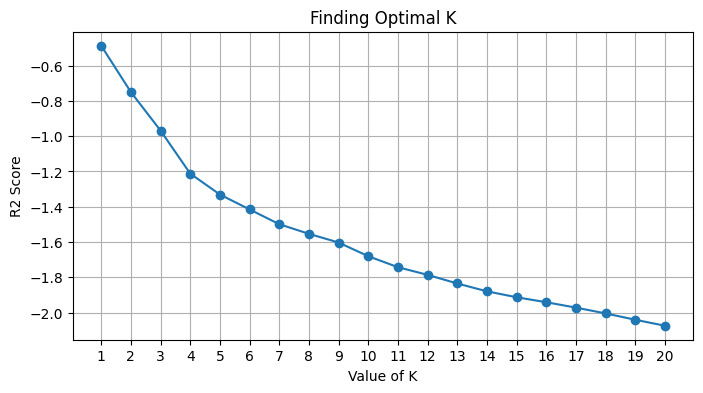

Best K found: 1
--- KNN Results ---
R2 Score: -0.4876
MAE: 27.5446
RMSE: 37.2130


In [231]:
# 1. Normalization (Scaling)
# fit on TRAIN, transform on TEST (to avoid data leakage)
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Justify K (Loop to find best K)
k_range = range(1, 21)
k_scores = []

for k in k_range:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    scores = knn.score(X_test_scaled, y_test) 
    k_scores.append(scores)
    
# Plot K results
plt.figure(figsize=(8, 4))
plt.plot(k_range, k_scores, marker='o')
plt.xlabel('Value of K')
plt.ylabel('R2 Score')
plt.title('Finding Optimal K')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# 3. Select Best K
best_k = k_range[np.argmax(k_scores)]
print(f"Best K found: {best_k}")

# 4. Final KNN Model
knn_final = KNeighborsRegressor(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)
y_pred_knn = knn_final.predict(X_test_scaled)

# 5. Evaluate
r2_knn = r2_score(y_test, y_pred_knn)
mae_knn = mean_absolute_error(y_test, y_pred_knn)         
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))  

print("--- KNN Results ---")
print(f"R2 Score: {r2_knn:.4f}")
print(f"MAE: {mae_knn:.4f}")      
print(f"RMSE: {rmse_knn:.4f}")    



# Why KNN fails to predict

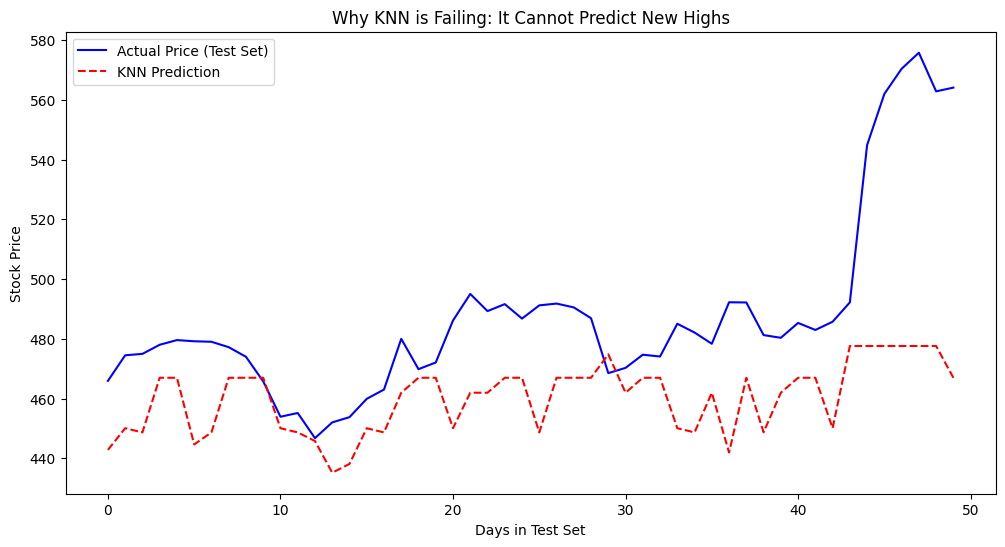

In [232]:
# Assuming you have trained 'knn_final' and 'lin_reg'

# 1. Generate Predictions for the graph
y_pred_knn_plot = knn_final.predict(X_test_scaled)

# 2. Plot Actual vs Predicted
plt.figure(figsize=(12, 6))
plt.plot(y_test.values, label='Actual Price (Test Set)', color='blue')
plt.plot(y_pred_knn_plot, label='KNN Prediction', color='red', linestyle='--')
plt.title('Why KNN is Failing: It Cannot Predict New Highs')
plt.xlabel('Days in Test Set')
plt.ylabel('Stock Price')
plt.legend()
plt.show()



In our analysis, we observed that the K-Nearest Neighbours (KNN) model struggled to accurately track the Close price of Netflix shares, particularly when the stock exhibited a strong upward or downward trend. This behavior can be attributed to two fundamental limitations of the algorithm in this context:

**Inability to Extrapolate Trends (The "Ceiling" Effect)**
KNN is a memory-based algorithm; it predicts values by averaging the targets of the most similar historical instances. Consequently,KNN cannot predict values outside the range of the training set.
* Example: If the maximum price in the training set was $500, but the stock rises to $550 in the test set, KNN will at best predict values near $500. It cannot mathematically project a trend upward like Linear Regression can.

**Lag and Smoothing**
By averaging the $k$ nearest neighbours, KNN tends to smooth out volatility. In a financial context, this results in a "lagging" effect where the model's predictions react slowly to sharp daily changes, often failing to capture the full amplitude of the daily price movement.

**Conclusion:**
While KNN is excellent for pattern recognition within known bounds, it is not well suited for predicting assets that are exploring new price levels (new highs or lows) absent from the training history.

# Comparison between KNN and Linear-Regression

--- Model Comparison ---


,Metric,Linear Regression,KNN
0,R² (Higher is better),0.9892,-0.4876
1,MAE (Lower is better),2.2536,27.5446
2,RMSE (Lower is better),3.1718,37.2130


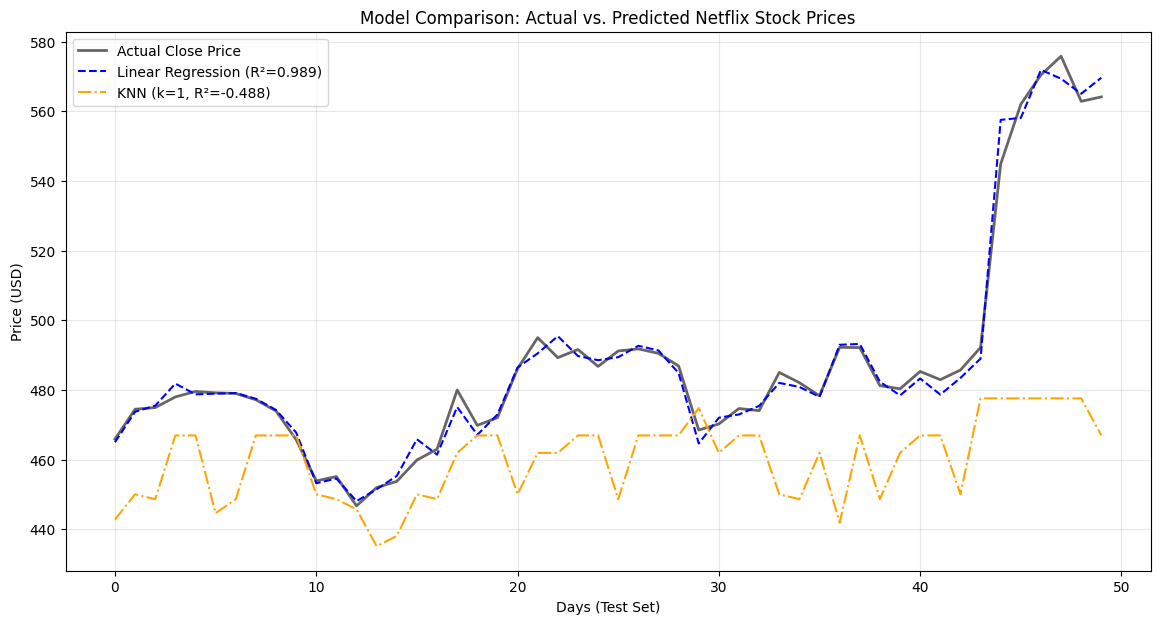

In [233]:
# 1. Calculate Metrics for Linear Regression
r2_lin = r2_score(y_test, y_pred_lr)
mae_lin = mean_absolute_error(y_test, y_pred_lr)
rmse_lin = np.sqrt(mean_squared_error(y_test, y_pred_lr))

# 2. Calculate Metrics for KNN (using the best k found)
r2_knn = r2_score(y_test, y_pred_knn)
mae_knn = mean_absolute_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))

# 3. Create a Comparison DataFrame
comparison_df = pd.DataFrame({
    'Metric': ['R² (Higher is better)', 'MAE (Lower is better)', 'RMSE (Lower is better)'],
    'Linear Regression': [r2_lin, mae_lin, rmse_lin],
    'KNN': [r2_knn, mae_knn, rmse_knn]
})

print("--- Model Comparison ---")
display(comparison_df)

# 4. Visual Comparison of Predictions
plt.figure(figsize=(14, 7))

# Plot Actual Values
plt.plot(y_test.values, label='Actual Close Price', color='black', alpha=0.6, linewidth=2)

# Plot Linear Regression Predictions
plt.plot(y_pred_lr, label=f'Linear Regression (R²={r2_lin:.3f})', color='blue', linestyle='--')

# Plot KNN Predictions
plt.plot(y_pred_knn, label=f'KNN (k={best_k}, R²={r2_knn:.3f})', color='orange', linestyle='-.')

plt.title('Model Comparison: Actual vs. Predicted Netflix Stock Prices')
plt.xlabel('Days (Test Set)')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Choice of the final model 

From the graph and metrics we can see that Linear-Regression is a far better choice than KNN as it as the better R^2 almost 0.99 and performs better in every metrics. We can see from the graph that the Linear-Regression graph is very accurate to the actual prices than the KNN model.

# Creating CSV File

In [234]:
final_prediction = pd.DataFrame({"price":y_pred_lr})
final_prediction.to_csv("precos_estimados.csv",index=False)

print("Saved precos_estimados.csv with", len(final_prediction), "rows.")

answer = pd.read_csv("precos_estimados.csv")
print(answer.head())

Saved precos_estimados.csv with 50 rows.
     price
0 464.9998
1 473.7477
2 475.4980
3 481.8293
4 478.7407


# Additional Task


## Defining Features and Target

In [235]:
# B) Daily Return (Percentage change from previous close)
df['Daily_Return'] = df['Close'].pct_change().shift(1)

# C) Short-Term Moving Averages (5 and 10 days)
df['MA_5'] = df['Close'].rolling(window=5).mean().shift(1)
df['MA_10'] = df['Close'].rolling(window=10).mean().shift(1)

# D) "Other Justified Variable": Volatility (Rolling Standard Deviation)
df['Volatility_5'] = df['Close'].rolling(window=5).std().shift(1)

df.dropna(inplace=True)
print(f"Data cleaned. Rows remaining: {len(df)}")

target = 'Close'

# Base Features (Original set)
features_base = ['Open', 'High', 'Low', 'Volume', 'Prev_Close', 'Day_of_Week', 'Amplitude']

# Extended Features (Base + New Derived Variables)
features_extended = features_base+ ['Daily_Return', 'MA_5', 'MA_10', 'Volatility_5']

# Define X and y
y = df[target]

# Split Data (Time-series split: keeping order is crucial)
X_train_idx, X_test_idx, y_train, y_test = train_test_split(df.index, y, test_size=0.2, shuffle=False)

# Prepare Base Data
X_train_base = df.loc[X_train_idx, features_base]
X_test_base  = df.loc[X_test_idx, features_base]

# Prepare Extended Data
X_train_ext = df.loc[X_train_idx, features_extended]
X_test_ext  = df.loc[X_test_idx, features_extended]

#Scaled Extended Data
X_train_scaled_ext = scaler.fit_transform(X_train_ext)
X_test_scaled_ext = scaler.transform(X_test_ext)

#Scaled Data
X_train_scaled_base = scaler.fit_transform(X_train_base)
X_test_scaled_base = scaler.transform(X_test_base)

Data cleaned. Rows remaining: 240


## Training and comparing Models

In [236]:
results = []

def get_metrics(model, X_tr, X_te, y_tr, y_te, name):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    return {
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_te, preds)),
        'MAE': mean_absolute_error(y_te, preds),
        'R2': r2_score(y_te, preds)
    }

# 1. Linear Regression Comparison
lr = LinearRegression()
results.append(get_metrics(lr, X_train_base, X_test_base, y_train, y_test, "LR (Base)"))
results.append(get_metrics(lr, X_train_ext, X_test_ext, y_train, y_test, "LR (Extended)"))

# 2. KNN Comparison (using k=1 as standard example)
knn = KNeighborsRegressor(n_neighbors=1)
results.append(get_metrics(knn, X_train_scaled_base, X_test_scaled_base, y_train, y_test, "KNN (Base)"))
results.append(get_metrics(knn, X_train_scaled_ext, X_test_scaled_ext, y_train, y_test, "KNN (Extended)"))

# --- 4. DISPLAY COMPARISON RESULTS ---
results_df = pd.DataFrame(results)

# Formatting for cleaner output
pd.options.display.float_format = '{:,.4f}'.format
print("--- Performance Comparison ---")
print(results_df)


best_model = results_df.loc[results_df['R2'].idxmax()]
print(f"\nBest performing model: {best_model['Model']} with R^2: {best_model['R2']:.4f}")

--- Performance Comparison ---
            Model    RMSE     MAE      R2
0       LR (Base)  3.2232  2.3330  0.9891
1   LR (Extended)  3.3164  2.3971  0.9885
2      KNN (Base) 35.6650 24.3137 -0.3304
3  KNN (Extended) 35.0828 23.9035 -0.2873

Best performing model: LR (Base) with R^2: 0.9891



### Conclusion:Model Performance and Feature Impact

After comparing "Base" feature against "Extended" to see if that adding more complexity improved the metrics it was found that,

#### **On Linear Regression**:The extended variables had a negative impact.
The "Base" model ($R^2$: 0.9891) slightly outperformed the "Extended" model ($R^2$: 0.9885).

Interpretation:The additional variables likely introduced noise or multicollinearity,leading to slight overfitting.Since the model already predicts 99% of variance, the extra features were not necessary and counterproductive.

#### **On KNN**:The extended variables had a tiny positive impact.
The "Extended" KNN improved slightly over the "Base" KNN (RMSE dropped from 35.66 to 35.08), but the model remained unusable ($R^2$ < 0).

Interpretation: While the extra dimensions helped separate neighbors slightly, they could not overcome KNN's fundamental inability to handle this specific dataset structure.

### Final Verdict
The Linear Regression (Base) model is the optimal choice. It offers the best accuracy with the simplest feature set, proving that for this specific problem, adding more complex "Extended" features does not improve the metrics.